# Property Sale Transactions: EDA

Explore the raw CSV landed by `make ingest` to decide:

1. the grain, cleaning rules, and data quality checks for the modeled layer, and
2. which question the output table should answer.

All fields are read as text, exactly as landed. The production rules and checks live in the pipeline; this notebook is the evidence behind them.

## Key takeaways

Snapshot analyzed: `data/raw/sales.csv` from WPRDC resource `5bbe6c55-bce6-4edb-9d04-68edeb6bf7b1`, 506,991 rows and 26 text columns, with sales through 2026-10-27.

1. **One row is one parcel on one deed**, not one transaction. The natural key is `(PARID, DEEDBOOK, DEEDPAGE, SALEDATE)`. `_id` changes on every reload.
2. **`PRICE` is a recorded consideration, not a market value.** $1 is the most common price, and 26.7% of rows are blank or below $1,000. Only 19.8% of rows are coded `0 VALID SALE`.
3. **Multi-parcel deeds repeat the deed price on every parcel row.** Summing row prices overstates dollar volume by 3.9x.
4. **Placeholder deed references** (`0/0`, `00/00`, `000/000`, blank) are shared by up to 957 unrelated parcels.
5. **175 `MUNICODE` values are 130 municipalities.** 49 codes are wards of Pittsburgh, McKeesport, Duquesne, and Clairton.
6. **The sale-code scheme changed around 2020.** Valid-sale counts are not comparable across years. This was the most surprising finding.
7. **Coverage starts in 2012, not 2013**, and 2026 is a partial year because of recording lag. One record date is `0212-08-01`.
8. **Small groups.** Half of municipality-years have fewer than 20 valid sales, so medians need a sample size next to them.

Sections 1-9 hold the evidence. Section 10 lists candidate questions and the chosen one, and section 11 summarizes cleaning rules and data quality checks.

In [2]:
%matplotlib inline
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
raw_dir = project_root / 'data' / 'raw'

pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.grid': True, 'grid.alpha': 0.3})
dollars = FuncFormatter(lambda value, _: f'${value:,.0f}')
thousands = FuncFormatter(lambda value, _: f'{value:,.0f}')

In [3]:
raw_path = raw_dir / "sales.csv"
if not raw_path.is_file():
    raise FileNotFoundError("No raw CSV yet. Run make ingest from the project root.")

sales = pd.read_csv(raw_path, dtype="string", keep_default_na=False)
print(f"Loaded {len(sales):,} records and {len(sales.columns)} columns.")
display(sales.head())

# In-memory copy only; the project database and CSV are never modified here.
con = duckdb.connect()
con.execute("CREATE TABLE raw_sales AS SELECT * FROM sales")


def q(query: str) -> pd.DataFrame:
    return con.sql(query).df()

Loaded 506,991 records and 26 columns.


,_id,PARID,FULL_ADDRESS,PROPERTYHOUSENUM,PROPERTYFRACTION,PROPERTYADDRESSDIR,PROPERTYADDRESSSTREET,PROPERTYADDRESSSUF,PROPERTYADDRESSUNITDESC,PROPERTYUNITNO,PROPERTYCITY,PROPERTYSTATE,PROPERTYZIP,SCHOOLCODE,SCHOOLDESC,MUNICODE,MUNIDESC,RECORDDATE,SALEDATE,PRICE,DEEDBOOK,DEEDPAGE,SALECODE,SALEDESC,INSTRTYP,INSTRTYPDESC
0,18884713,1010G00075000000,"0 HILL ST, SOUTH PARK, PA 15129",0,,,HILL,ST,,,SOUTH PARK,PA,15129,37,South Park,945,South Park,2022-07-06,2022-06-21,1.0,18965,534,H,MULTI-PARCEL SALE,DE,DEED
1,18884714,1065H00275000000,"0 HENRY RD, SEWICKLEY, PA 15143",0,,,HENRY,RD,,,SEWICKLEY,PA,15143,27,North Allegheny,884,Franklin Park,2026-08-07,2026-07-31,10000.0,20514,532,H,MULTI-PARCEL SALE,CO,CORRECTIVE DEED
2,18884715,1065H00279000000,"0 HENRY RD, SEWICKLEY, PA 15143",0,,,HENRY,RD,,,SEWICKLEY,PA,15143,27,North Allegheny,884,Franklin Park,2026-08-07,2026-07-31,10000.0,20514,532,H,MULTI-PARCEL SALE,CO,CORRECTIVE DEED
3,18884716,1075F00108000000,"4720 HIGHPOINT DR, GIBSONIA, PA 15044",4720,,,HIGHPOINT,DR,,,GIBSONIA,PA,15044,20,Hampton Township,914,Hampton,2012-09-27,2012-09-27,120000.0,15020,356,3,LOVE AND AFFECTION SALE,DE,DEED
4,18884717,0011A00237000000,"0 LOMBARD ST, PITTSBURGH, PA 15219",0,,,LOMBARD,ST,,,PITTSBURGH,PA,15219,47,Pittsburgh,103,3rd Ward - PITTSBURGH,2015-01-06,2015-01-06,14783.0,TR15,00002,GV,GOVERNMENT SALE,TS,TREASURER DEED


## 1. Grain and keys

What does one row represent: a parcel, a deed, or a transaction? Which columns, if any, identify a row?

In [4]:
non_id_columns = ", ".join(f'"{name}"' for name in sales.columns if name != "_id")
display(q(f"""
    SELECT
        count(*) AS records,
        count(DISTINCT _id) AS distinct_ids,
        count(DISTINCT PARID) AS distinct_parcels,
        count(DISTINCT ({non_id_columns})) AS distinct_records_ignoring_id,
        count(DISTINCT (PARID, DEEDBOOK, DEEDPAGE)) AS distinct_parcel_deed,
        count(DISTINCT (PARID, SALEDATE, DEEDBOOK, DEEDPAGE)) AS distinct_parcel_date_deed,
        count(DISTINCT (PARID, SALEDATE)) AS distinct_parcel_date
    FROM raw_sales
"""))

# Same parcel and sale date, different deed: separate instruments or corrections?
display(q("""
    WITH repeated AS (
        SELECT PARID, SALEDATE FROM raw_sales GROUP BY ALL HAVING count(*) > 1
    )
    SELECT r.PARID, r.SALEDATE, r.PRICE, r.DEEDBOOK, r.DEEDPAGE, r.SALECODE, r.SALEDESC, r.INSTRTYPDESC
    FROM raw_sales r JOIN repeated USING (PARID, SALEDATE)
    ORDER BY r.PARID, r.SALEDATE, r.DEEDBOOK, r.DEEDPAGE
    LIMIT 12
"""))

,records,distinct_ids,distinct_parcels,distinct_records_ignoring_id,distinct_parcel_deed,distinct_parcel_date_deed,distinct_parcel_date
0,506991,506991,313967,506991,506990,506991,503847


,PARID,SALEDATE,PRICE,DEEDBOOK,DEEDPAGE,SALECODE,SALEDESC,INSTRTYPDESC
0,0001C01662111400,2024-01-08,1.0,19553,417,3,LOVE AND AFFECTION SALE,DEED
1,0001C01662111400,2024-01-08,1.0,19557,397,3,LOVE AND AFFECTION SALE,DEED
2,0001C01662221100,2024-01-08,1.0,19553,483,3,LOVE AND AFFECTION SALE,DEED
3,0001C01662221100,2024-01-08,1.0,19557,413,3,LOVE AND AFFECTION SALE,DEED
4,0001C01662A00500,2024-01-08,1.0,19553,431,3,LOVE AND AFFECTION SALE,DEED
5,0001C01662A00500,2024-01-08,1.0,19557,405,3,LOVE AND AFFECTION SALE,DEED
6,0001D00184000000,2012-04-16,1.0,14862,286,9,OTHER INVALID SALES INDICATED,DEED
7,0001D00184000000,2012-04-16,2610000.0,14862,294,AA,SALE NOT ANALYZED,DEED
8,0001N00009000000,2022-05-05,1.0,18916,463,H,MULTI-PARCEL SALE,DEED
9,0001N00009000000,2022-05-05,1.0,18921,235,H,MULTI-PARCEL SALE,DEED


**Findings**

- 506,991 rows covering 313,967 parcels. `_id` is unique but is reassigned on every WPRDC reload, so it is not a durable key.
- No exact duplicate rows once `_id` is ignored.
- **One row = one parcel on one deed.** `(PARID, DEEDBOOK, DEEDPAGE, SALEDATE)` is unique. `(PARID, DEEDBOOK, DEEDPAGE)` alone is unique except for one pair with a blank deed reference.
- 3,144 rows share a parcel and sale date with another row but have a different deed (for example, a $1 transfer and a $2.6M sale recorded the same day). These are separate instruments, not duplicates.
- **Rule:** use `(PARID, DEEDBOOK, DEEDPAGE, SALEDATE)` as the natural key of the cleaned table and test that it stays unique.

## 2. Completeness

Blank means empty or whitespace only. Empty strings were preserved on load, so `NULL` never appears in the raw text.

In [5]:
blanks = sales.apply(lambda column: column.str.strip().eq("").sum())
padded = sales.apply(lambda column: column.ne(column.str.strip()).sum())
completeness = pd.DataFrame({
    "blank": blanks,
    "blank_pct": (blanks / len(sales) * 100).round(2),
    "leading_or_trailing_space": padded,
})
display(completeness.sort_values("blank", ascending=False))

,blank,blank_pct,leading_or_trailing_space
PROPERTYUNITNO,495027,97.64,1
PROPERTYFRACTION,494909,97.62,506991
PROPERTYADDRESSUNITDESC,494643,97.56,0
PROPERTYADDRESSDIR,485949,95.85,0
PRICE,3106,0.61,0
PROPERTYADDRESSSUF,2101,0.41,0
RECORDDATE,1248,0.25,0
DEEDPAGE,579,0.11,8
DEEDBOOK,567,0.11,4
PROPERTYADDRESSSTREET,16,0.00,153


**Findings**

- Core analytical fields are complete: `PARID`, `SALEDATE`, `MUNICODE`, `MUNIDESC`, `SALECODE`, and `INSTRTYP` have no blanks.
- `PRICE` is blank on 3,106 rows (0.6%), `RECORDDATE` on 1,248 (mostly 2012-2016 sales), and `DEEDBOOK`/`DEEDPAGE` on about 570.
- Unit, fraction, and direction address parts are blank on 95-98% of rows, as expected for single-family addresses. `PROPERTYFRACTION` is a single space on every row.
- `MUNIDESC` has trailing spaces on 360,164 rows (71%), so grouping on the raw text would be fragile.
- **Rules:** trim text fields; convert blank `PRICE`/`RECORDDATE`/deed references to `NULL`; never treat a blank price as $0.

## 3. Formats and code consistency

Check whether text fields parse into their intended types, and whether codes map one-to-one to their descriptions.

In [6]:
display(q(r"""
    SELECT
        count(*) FILTER (WHERE try_strptime(SALEDATE, '%Y-%m-%d') IS NULL) AS saledate_not_iso,
        count(*) FILTER (WHERE RECORDDATE <> '' AND try_strptime(RECORDDATE, '%Y-%m-%d') IS NULL) AS recorddate_not_iso,
        count(*) FILTER (WHERE PRICE <> '' AND try_cast(PRICE AS DOUBLE) IS NULL) AS price_not_numeric,
        count(*) FILTER (WHERE try_cast(PRICE AS DOUBLE) % 1 <> 0) AS price_with_cents,
        count(*) FILTER (WHERE NOT regexp_full_match(PARID, '[0-9A-Z]{16}')) AS parid_not_16_alnum,
        count(*) FILTER (WHERE NOT regexp_full_match(PROPERTYZIP, '[0-9]{5}')) AS zip_not_5_digits,
        count(*) FILTER (WHERE PROPERTYSTATE <> 'PA') AS state_not_pa,
        count(*) FILTER (WHERE NOT regexp_full_match(MUNICODE, '[0-9]+')) AS municode_not_numeric
    FROM raw_sales
"""))

# Each code should map to exactly one description (after trimming).
code_pairs = {"MUNICODE": "MUNIDESC", "SCHOOLCODE": "SCHOOLDESC", "SALECODE": "SALEDESC", "INSTRTYP": "INSTRTYPDESC"}
for code, desc in code_pairs.items():
    many = q(f"SELECT count(*) AS n FROM (SELECT {code} FROM raw_sales GROUP BY 1 HAVING count(DISTINCT trim({desc})) > 1)")["n"][0]
    print(f"{code}: {many} codes with more than one description")

display(q("""
    SELECT count(DISTINCT MUNICODE) AS municipality_codes,
           count(DISTINCT SALECODE) AS sale_codes,
           count(DISTINCT SALECODE) FILTER (WHERE SALEDESC = 'OTHER') AS sale_codes_described_as_other
    FROM raw_sales
"""))

,saledate_not_iso,recorddate_not_iso,price_not_numeric,price_with_cents,parid_not_16_alnum,zip_not_5_digits,state_not_pa,municode_not_numeric
0,0,0,0,0,0,1,0,0


MUNICODE: 0 codes with more than one description
SCHOOLCODE: 0 codes with more than one description
SALECODE: 0 codes with more than one description
INSTRTYP: 0 codes with more than one description


,municipality_codes,sale_codes,sale_codes_described_as_other
0,175,47,21


**Findings**

- All dates are ISO `YYYY-MM-DD`, although the data dictionary says dd/mm/yyyy. Parse with an explicit ISO format and fail on anything else rather than guessing.
- `PRICE` is always numeric text such as `150000.0`, with no cents, no negatives, and no currency symbols.
- `PARID` is always 16 alphanumeric characters, `PROPERTYSTATE` is always `PA`, and one row has a malformed ZIP (not used for analysis).
- Every code maps to exactly one description after trimming. However, 21 of 47 `SALECODE` values are described only as `OTHER`, so the description alone cannot drive filtering. Filter on codes instead.

## 4. Dates

The dataset page says "2013-present". Check actual coverage, the gap between sale and recording, and whether the latest months are complete.

In [7]:
# DuckDB names are case-insensitive, so parsed columns need names distinct from raw ones.
con.execute("""
    CREATE OR REPLACE VIEW typed AS
    SELECT
        *,
        SALEDATE::DATE AS sale_date,
        try_cast(NULLIF(RECORDDATE, '') AS DATE) AS record_date,
        try_cast(NULLIF(PRICE, '') AS DOUBLE) AS price_usd,
        try_cast(NULLIF(RECORDDATE, '') AS DATE) - SALEDATE::DATE AS record_lag_days
    FROM raw_sales
""")

display(q("""
    SELECT min(sale_date) AS first_sale, max(sale_date) AS last_sale,
           min(record_date) AS first_record, max(record_date) AS last_record,
           count(*) FILTER (WHERE record_date IS NULL) AS missing_record_date,
           count(*) FILTER (WHERE record_lag_days < 0) AS recorded_before_sale,
           count(*) FILTER (WHERE record_lag_days > 365) AS recorded_over_1y_after_sale,
           median(record_lag_days) AS median_lag_days,
           quantile_cont(record_lag_days, 0.95) AS p95_lag_days
    FROM typed
"""))

# Where are missing record dates concentrated?
display(q("""
    SELECT year(sale_date) AS sale_year, count(*) AS missing_record_date
    FROM typed WHERE record_date IS NULL GROUP BY 1 ORDER BY 1
""").set_index("sale_year").T)

,first_sale,last_sale,first_record,last_record,missing_record_date,recorded_before_sale,recorded_over_1y_after_sale,median_lag_days,p95_lag_days
0,2012-01-01,2026-10-27,212-08-01,2026-10-29,1248,730,2719,6.0,57.0


sale_year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2026
missing_record_date,190,332,326,215,150,16,12,1,1,3,1,1


In [8]:
# The earliest record date above is year 212: list implausible record dates.
display(q("""
    SELECT PARID, SALEDATE, RECORDDATE, PRICE, DEEDBOOK, DEEDPAGE, SALEDESC
    FROM typed
    WHERE record_date < DATE '2000-01-01' OR record_date > current_date
    ORDER BY record_date LIMIT 10
"""))

,PARID,SALEDATE,RECORDDATE,PRICE,DEEDBOOK,DEEDPAGE,SALEDESC
0,0033H00367000000,2012-08-01,0212-08-01,1658.0,14965,360,SHERIFF SALE


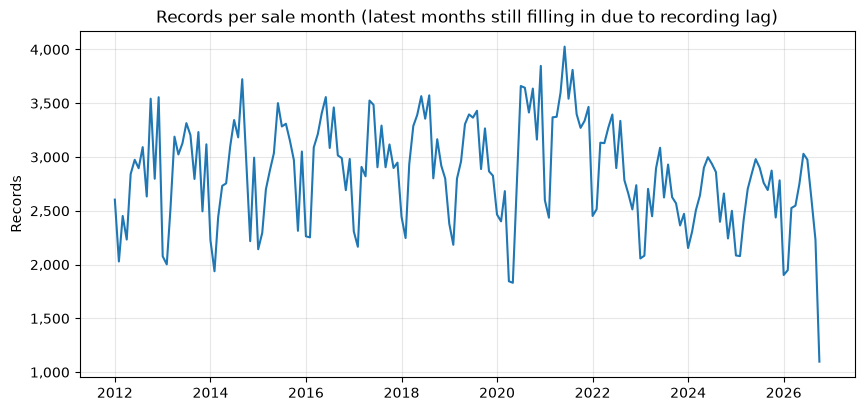

,sale_month,records
175,2026-08-01,2613
176,2026-09-01,2231
177,2026-10-01,1098


In [9]:
monthly = q("""
    SELECT date_trunc('month', sale_date) AS sale_month, count(*) AS records
    FROM typed GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots()
ax.plot(monthly["sale_month"], monthly["records"])
ax.set_title("Records per sale month (latest months still filling in due to recording lag)")
ax.set_ylabel("Records")
ax.yaxis.set_major_formatter(thousands)
plt.show()
display(monthly.tail(3))

**Findings**

- Sales run from **2012-01-01** to 2026-10-27, not "2013-present" as described.
- Recording usually follows the sale quickly (median 6 days, 95th percentile 57 days). Still, 730 rows are recorded before the sale date and 2,719 more than a year after.
- **One `RECORDDATE` is `0212-08-01`**, an obvious typo for 2012-08-01 on a sheriff sale. It parses as a valid date, so a type check alone would not catch it.
- The newest months are incomplete because of recording lag (October 2026 has 1,098 records versus roughly 2,500-3,000 normally), so 2026 is a partial year.
- The monthly series shows seasonality (summer peaks), a dip in April 2020, and a 2021 peak.
- **Rules:** use `SALEDATE` as the event date and `RECORDDATE` as nullable metadata. Null and flag record dates before 2000. Exclude the current partial year from annual outputs.

## 5. Prices

Is `PRICE` a usable market price on every row? Look for blanks, nominal amounts, and extreme values.

In [10]:
display(q("""
    SELECT count(*) FILTER (WHERE price_usd IS NULL) AS blank,
           count(*) FILTER (WHERE price_usd < 0) AS negative,
           count(*) FILTER (WHERE price_usd = 0) AS zero,
           count(*) FILTER (WHERE price_usd = 1) AS one_dollar,
           count(*) FILTER (WHERE price_usd > 1 AND price_usd < 1000) AS between_1_and_1000,
           count(*) FILTER (WHERE price_usd >= 1000) AS at_least_1000,
           round(100.0 * count(*) FILTER (WHERE price_usd IS NULL OR price_usd < 1000) / count(*), 1) AS pct_below_1000_or_blank,
           median(price_usd) AS median_all_rows
    FROM typed
"""))
display(q("SELECT PRICE, count(*) AS records FROM raw_sales GROUP BY 1 ORDER BY 2 DESC LIMIT 10"))
display(q("""
    SELECT PARID, SALEDATE, price_usd, MUNIDESC, SALEDESC, INSTRTYPDESC, DEEDBOOK, DEEDPAGE
    FROM typed ORDER BY price_usd DESC NULLS LAST LIMIT 8
"""))

,blank,negative,zero,one_dollar,between_1_and_1000,at_least_1000,pct_below_1000_or_blank,median_all_rows
0,3106,0,15802,105600,11006,371477,26.7,93500.0


,PRICE,records
0,1.0,105600
1,0.0,15802
2,10.0,7331
3,150000.0,3328
4,,3106
5,100000.0,2841
6,50000.0,2829
7,200000.0,2646
8,125000.0,2627
9,175000.0,2515


,PARID,SALEDATE,price_usd,MUNIDESC,SALEDESC,INSTRTYPDESC,DEEDBOOK,DEEDPAGE
0,0002J00104000000,2016-01-18,148752900.0,1st Ward - PITTSBURGH,QUIT CLAIM,SPECIAL WARRANTY,16267,254
1,0009P00050000000,2013-08-09,124400000.0,2nd Ward - PITTSBURGH,VALID SALE,SPECIAL WARRANTY,15334,322
2,0023L00060000000,2022-07-29,82000000.0,22nd Ward - PITTSBURGH,MULTI-PARCEL SALE,SPECIAL WARRANTY,19002,351
3,0023L00020000000,2022-07-29,82000000.0,22nd Ward - PITTSBURGH,MULTI-PARCEL SALE,SPECIAL WARRANTY,19002,351
4,0001G00239000000,2017-02-13,81325000.0,1st Ward - PITTSBURGH,QUIT CLAIM,SPECIAL WARRANTY,16701,296
5,1998C00004000000,2024-05-30,79000000.0,Marshall,CORPORATION TRANSFER,SPECIAL WARRANTY,19690,378
6,1175A00075000000,2021-12-03,76206600.0,Findlay,CORRECTIVE DEED / DUPLICATE SALE,SPECIAL WARRANTY,18741,86
7,0743M00275000000,2026-08-28,75500000.0,Monroeville,MULTI-PARCEL SALE,SPECIAL WARRANTY,20559,517


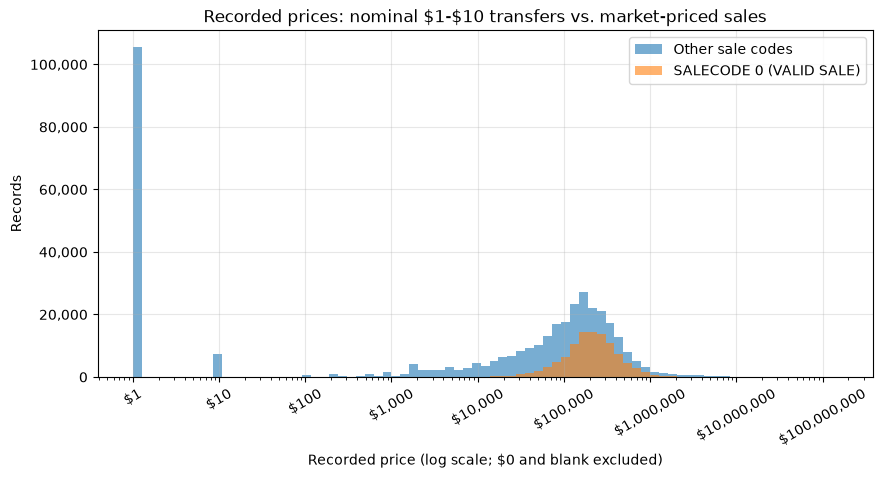

In [11]:
prices = q("SELECT price_usd, SALECODE = '0' AS valid_sale FROM typed WHERE price_usd > 0")
bins = np.logspace(0, np.log10(prices["price_usd"].max()), 80)
fig, ax = plt.subplots()
ax.hist(prices.loc[~prices["valid_sale"], "price_usd"], bins=bins, alpha=0.6, label="Other sale codes")
ax.hist(prices.loc[prices["valid_sale"], "price_usd"], bins=bins, alpha=0.6, label="SALECODE 0 (VALID SALE)")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(dollars)
ax.tick_params(axis="x", labelrotation=30)
ax.yaxis.set_major_formatter(thousands)
ax.set_title(r"Recorded prices: nominal \$1-\$10 transfers vs. market-priced sales")
ax.set_xlabel("Recorded price (log scale; $0 and blank excluded)")
ax.set_ylabel("Records")
ax.legend()
plt.show()

**Findings**

- **$1 is the most common price** (105,600 rows), followed by $0 (15,802) and $10 (7,331). In total, 26.7% of rows are blank or below $1,000.
- The median over all rows ($93,500) blends nominal transfers with market sales, so it is meaningless.
- The distribution is clearly bimodal. Nominal transfers sit at $0-$10, and market-priced sales are centered near $150k-$250k.
- The top prices ($75M-$149M) are downtown and commercial deeds, several coded as quit claims, corporate transfers, or multi-parcel sales rather than valid sales.
- **Rule:** `PRICE` is a recorded consideration, not a market value. Market analysis needs a validity filter (section 6), not just a price floor.

## 6. Sale codes and instrument types

`SALECODE`/`SALEDESC` is the county assessor's validity flag for a transfer. Which codes represent arm's-length market sales?

In [12]:
sale_codes = q("""
    SELECT SALECODE, SALEDESC, count(*) AS records,
           round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct,
           round(100.0 * count(*) FILTER (WHERE price_usd IS NULL OR price_usd < 1000) / count(*), 1) AS pct_below_1000_or_blank,
           median(price_usd) AS median_price
    FROM typed GROUP BY ALL ORDER BY records DESC
""")
display(sale_codes.head(20))

,SALECODE,SALEDESC,records,pct,pct_below_1000_or_blank,median_price
0,3,LOVE AND AFFECTION SALE,104725,20.66,98.0,1.0
1,0,VALID SALE,100487,19.82,0.0,209900.0
2,H,MULTI-PARCEL SALE,67503,13.31,33.7,64000.0
3,14,TIME ON MARKET (INSUFF/EXCESS),45355,8.95,0.8,105000.0
4,36,QUIT CLAIM,40185,7.93,1.4,134900.0
5,9,OTHER INVALID SALES INDICATED,30924,6.10,3.7,194657.5
6,99,CORRECTIVE DEED / DUPLICATE SALE,16742,3.30,3.8,182500.0
7,AA,SALE NOT ANALYZED,16419,3.24,1.3,130000.0
8,1,SHERIFF SALE,15130,2.98,0.3,6000.0
9,UR,OTHER,12655,2.50,0.2,120000.0


In [13]:
# Even "valid" sales can carry nominal prices; how many, and with which instruments?
display(q("""
    SELECT count(*) AS valid_sales,
           count(*) FILTER (WHERE price_usd IS NULL) AS blank_price,
           count(*) FILTER (WHERE price_usd < 1000) AS below_1000,
           count(*) FILTER (WHERE price_usd < 10000) AS below_10000,
           count(*) FILTER (WHERE price_usd >= 10000000) AS at_least_10m
    FROM typed WHERE SALECODE = '0'
"""))
display(q("""
    SELECT INSTRTYP, INSTRTYPDESC, count(*) AS records,
           count(*) FILTER (WHERE SALECODE = '0') AS valid_sales,
           median(price_usd) FILTER (WHERE SALECODE = '0') AS median_valid_price
    FROM typed GROUP BY ALL ORDER BY records DESC LIMIT 12
"""))

,valid_sales,blank_price,below_1000,below_10000,at_least_10m
0,100487,0,37,195,5


,INSTRTYP,INSTRTYPDESC,records,valid_sales,median_valid_price
0,DE,DEED,294449,62444,205000.0
1,SW,SPECIAL WARRANTY,121130,28078,225000.0
2,GW,GENERAL WARRANTY,24444,7335,199000.0
3,QC,QUIT CLAIM,19450,79,20000.0
4,SD,SHERIFF DEED,16175,2,98453.5
5,FD,FIDUCIARY DEED,8467,1679,181000.0
6,TS,TREASURER DEED,5921,3,975.0
7,WD,WARRANTY DEED,4914,675,159900.0
8,CO,CORRECTIVE DEED,4600,119,189250.0
9,MH,Mobile Home Sale,2513,0,NaN


**Findings**

- Only **100,487 rows (19.8%)** are coded `0 VALID SALE`, the assessor's arm's-length flag. Their median price is $209,900.
- `3 LOVE AND AFFECTION` (family transfers) is the largest code, and 98% of those rows are below $1,000.
- Sheriff, city treasurer, and government sales have medians of $2k-$6k, which reflects distress rather than market value.
- Codes such as `14 TIME ON MARKET` or `9 OTHER INVALID` carry market-looking prices but were judged not arm's-length by the assessor.
- Valid sales are clean on price: none are blank, and only 37 are below $1,000.
- Instrument type is consistent with the code: quit claim, sheriff, and treasurer deeds are almost never valid sales.
- **Rule:** define a market sale as `SALECODE = '0'`, plus a $1,000 price floor as a guard. Filter on the code, not on the description text.

## 7. Multi-parcel deeds

A deed (`DEEDBOOK`, `DEEDPAGE`) can convey several parcels. Is the price per parcel or per deed? Are deed references always real?

In [14]:
# The largest "deeds" are placeholders, not real instruments.
display(q("""
    SELECT DEEDBOOK, DEEDPAGE, count(*) AS records, count(DISTINCT PARID) AS parcels,
           min(SALEDATE) AS first_sale, max(SALEDATE) AS last_sale, count(DISTINCT PRICE) AS prices
    FROM raw_sales GROUP BY ALL ORDER BY records DESC LIMIT 8
"""))

# Real reference: non-zero book (or a TR## treasurer book) and non-zero page.
REAL_DEED = r"""regexp_full_match(trim(DEEDBOOK), '[0-9]*[1-9][0-9]*|TR[0-9]{2}')
            AND regexp_full_match(trim(DEEDPAGE), '[0-9]*[1-9][0-9]*')"""
display(q(f"""
    SELECT count(*) FILTER (WHERE NOT ({REAL_DEED})) AS placeholder_or_irregular_deed_ref,
           count(*) FILTER (WHERE DEEDBOOK LIKE 'TR%') AS treasurer_deed_book
    FROM raw_sales
"""))

,DEEDBOOK,DEEDPAGE,records,parcels,first_sale,last_sale,prices
0,0,0,957,957,2012-01-01,2026-10-14,9
1,00,00,736,736,2012-01-01,2026-10-08,6
2,,,546,545,2012-01-01,2024-11-06,17
3,000,000,270,270,2012-08-01,2026-10-22,5
4,18292,134,173,173,2020-12-16,2020-12-16,1
5,16294,325,173,173,2015-12-30,2015-12-30,1
6,16339,1,155,155,2016-03-31,2016-03-31,2
7,15478,8,134,134,2013-12-31,2013-12-31,1


,placeholder_or_irregular_deed_ref,treasurer_deed_book
0,3065,5060


In [15]:
# One row per real deed.
con.execute(f"""
    CREATE OR REPLACE VIEW deeds AS
    SELECT trim(DEEDBOOK) AS deed_book, trim(DEEDPAGE) AS deed_page,
           count(*) AS parcels,
           count(DISTINCT PRICE) AS prices,
           count(DISTINCT MUNICODE) AS municipalities,
           bool_or(SALECODE = 'H') AS has_multi_parcel_code,
           max(price_usd) AS max_price
    FROM typed
    WHERE {REAL_DEED}
    GROUP BY 1, 2
""")
display(q("""
    SELECT count(*) FILTER (WHERE parcels > 1) AS multi_parcel_deeds,
           sum(parcels) FILTER (WHERE parcels > 1) AS rows_in_multi_parcel_deeds,
           count(*) FILTER (WHERE parcels > 1 AND prices = 1) AS same_price_on_every_row,
           count(*) FILTER (WHERE parcels > 1 AND municipalities > 1) AS span_municipalities,
           count(*) FILTER (WHERE parcels > 1 AND NOT has_multi_parcel_code) AS multi_without_code_h,
           count(*) FILTER (WHERE parcels = 1 AND has_multi_parcel_code) AS single_row_with_code_h
    FROM deeds
"""))

# Example: one deed price repeated on every parcel row.
display(q("""
    SELECT t.DEEDBOOK, t.DEEDPAGE, t.PARID, t.MUNIDESC, t.SALEDATE, t.PRICE, t.SALEDESC
    FROM typed t
    JOIN (SELECT deed_book, deed_page FROM deeds
          WHERE parcels BETWEEN 3 AND 5 AND prices = 1 AND max_price > 100000
          ORDER BY deed_book DESC, deed_page LIMIT 1) d
      ON trim(t.DEEDBOOK) = d.deed_book AND trim(t.DEEDPAGE) = d.deed_page
"""))

,multi_parcel_deeds,rows_in_multi_parcel_deeds,same_price_on_every_row,span_municipalities,multi_without_code_h,single_row_with_code_h
0,25178,69894.0,24418,1882,1153,1494


,DEEDBOOK,DEEDPAGE,PARID,MUNIDESC,SALEDATE,PRICE,SALEDESC
0,20594,578,0745N00091000000,Monroeville,2026-09-16,420000.0,MULTI-PARCEL SALE
1,20594,578,0746A00398000000,Monroeville,2026-09-16,420000.0,MULTI-PARCEL SALE
2,20594,578,0745N00097000000,Monroeville,2026-09-16,420000.0,MULTI-PARCEL SALE
3,20594,578,0640S00398000000,Monroeville,2026-09-16,420000.0,MULTI-PARCEL SALE
4,20594,578,0640S00402000000,Monroeville,2026-09-16,420000.0,MULTI-PARCEL SALE


In [16]:
display(q("""
    WITH multi AS (SELECT * FROM deeds WHERE parcels > 1 AND prices = 1)
    SELECT round(sum(max_price * parcels) / 1e9, 2) AS naive_row_sum_billions,
           round(sum(max_price) / 1e9, 2) AS deed_level_sum_billions,
           round(sum(max_price * parcels) / sum(max_price), 2) AS overstatement_factor
    FROM multi
"""))

display(q("""
    SELECT count(*) AS valid_sale_rows,
           count(*) FILTER (WHERE d.parcels > 1) AS in_multi_row_deed,
           count(*) FILTER (WHERE d.deed_book IS NULL) AS unknown_deed_ref
    FROM typed t
    LEFT JOIN deeds d ON trim(t.DEEDBOOK) = d.deed_book AND trim(t.DEEDPAGE) = d.deed_page
    WHERE t.SALECODE = '0'
"""))

,naive_row_sum_billions,deed_level_sum_billions,overstatement_factor
0,24.72,6.36,3.89


,valid_sale_rows,in_multi_row_deed,unknown_deed_ref
0,100487,140,22


**Findings**

- **Placeholder references** (`0/0`, `00/00`, blank, ...) are shared by up to 957 unrelated parcels sold years apart; 3,065 rows have one. `TR##` books (5,060 rows) are real treasurer deeds and are kept.
- **Multi-parcel deeds repeat the deed price on every row.** 25,178 real deeds cover 69,894 rows, and 97% show the same price on each row. Summing those rows gives $24.7B versus $6.4B counted once per deed, a **3.9x overstatement**.
- Code `H` (multi-parcel) is unreliable: 1,153 multi-row deeds lack it and 1,494 single-row deeds have it. Count parcels from deed references instead.
- 1,882 multi-parcel deeds span municipalities, so their price cannot be assigned to one place.
- Few valid sales are affected: 140 are on multi-row deeds and 22 have unknown references (six of those pass the price floor).
- **Rules:** set placeholder references to `NULL` (keeping the originals for the natural key) and never group them together. Exclude known multi-parcel deeds from price statistics. Keep unknown references, but flag them.

## 8. Municipalities

Allegheny County has 130 municipalities. How do the `MUNICODE` values map to them, and are there enough sales per municipality-year for a stable median?

In [17]:
munis = q("""
    SELECT MUNICODE, MUNIDESC, count(*) AS records
    FROM raw_sales GROUP BY MUNICODE, MUNIDESC ORDER BY MUNICODE::INT
""")
munis["ward_of"] = munis["MUNIDESC"].str.extract(r"Ward\s*-\s*(.+?)\s*$", expand=False)
print(f"{len(munis)} municipality codes; {munis['ward_of'].notna().sum()} are wards of a city.")
display(munis.groupby(munis["ward_of"].fillna("(not a ward)")).agg(
    codes=("MUNICODE", "count"), first_code=("MUNICODE", "min"), last_code=("MUNICODE", "max"),
    records=("records", "sum"),
))
display(munis[munis["ward_of"].notna()].head(4))
print("Examples of trailing spaces:", munis.loc[munis["MUNIDESC"].ne(munis["MUNIDESC"].str.strip()), "MUNIDESC"].head(3).map(repr).tolist())
print("Doubled apostrophes:", munis.loc[munis["MUNIDESC"].str.contains("''", regex=False), "MUNIDESC"].map(repr).tolist())
print("Mixed case:", munis.loc[munis["MUNIDESC"].str.contains("Mc", regex=False), "MUNIDESC"].head(2).map(repr).tolist())

175 municipality codes; 49 are wards of a city.


,codes,first_code,last_code,records
ward_of,,,,
(not a ward),126,801,953,369600
CLAIRTON,2,201,202,4368
DUQUESNE,3,301,303,2164
McKEESPORT,12,401,412,8248
PITTSBURGH,32,101,132,122611


,MUNICODE,MUNIDESC,records,ward_of
0,101,1st Ward - PITTSBURGH,983,PITTSBURGH
1,102,2nd Ward - PITTSBURGH,1647,PITTSBURGH
2,103,3rd Ward - PITTSBURGH,946,PITTSBURGH
3,104,4th Ward - PITTSBURGH,4031,PITTSBURGH


Examples of trailing spaces: ["'2nd Ward - McKEESPORT  '", "'4th Ward - McKEESPORT '", "'Aspinwall  '"]
Doubled apostrophes: ['"O\'\'Hara  "']
Mixed case: ["'1st Ward  - McKEESPORT'", "'2nd Ward - McKEESPORT  '"]


In [18]:
con.execute(r"""
    CREATE OR REPLACE VIEW candidate AS
    SELECT t.*,
           CASE WHEN regexp_matches(MUNIDESC, 'Ward\s*-\s*')
                THEN upper(trim(regexp_extract(MUNIDESC, 'Ward\s*-\s*(.+)$', 1)))
                ELSE replace(trim(MUNIDESC), '''''', '''') END AS municipality,
           year(sale_date) AS sale_year,
           d.parcels AS deed_parcels
    FROM typed t
    LEFT JOIN deeds d ON trim(t.DEEDBOOK) = d.deed_book AND trim(t.DEEDPAGE) = d.deed_page
""")

display(q("""
    SELECT 'all records' AS step, count(*) AS records FROM candidate
    UNION ALL SELECT 'SALECODE 0 (VALID SALE)', count(*) FROM candidate WHERE SALECODE = '0'
    UNION ALL SELECT '+ price >= $1,000', count(*) FROM candidate WHERE SALECODE = '0' AND price_usd >= 1000
    UNION ALL SELECT '+ no known multi-parcel deed', count(*) FROM candidate
        WHERE SALECODE = '0' AND price_usd >= 1000 AND (deed_parcels = 1 OR deed_parcels IS NULL)
    UNION ALL SELECT '+ full sale years 2012-2025 (EDA)', count(*) FROM candidate
        WHERE SALECODE = '0' AND price_usd >= 1000 AND (deed_parcels = 1 OR deed_parcels IS NULL) AND sale_year <= 2025
"""))
print('Municipalities after ward roll-up:', q('SELECT count(DISTINCT municipality) AS count FROM candidate')['count'][0])

,step,records
0,all records,506991
1,SALECODE 0 (VALID SALE),100487
2,"+ price >= $1,000",100450
3,+ no known multi-parcel deed,100313
4,+ full sale years 2012-2025 (EDA),93266


Municipalities after ward roll-up: 130


In [19]:
con.execute("""
    CREATE OR REPLACE VIEW market_sales AS
    SELECT * FROM candidate
    WHERE SALECODE = '0' AND price_usd >= 1000
      AND (deed_parcels = 1 OR deed_parcels IS NULL)
""")
group_sizes = q("""
    SELECT municipality, sale_year, count(*) AS sales
    FROM market_sales WHERE sale_year <= 2025 GROUP BY ALL
""")
possible = q('SELECT count(DISTINCT municipality) * 14 AS n FROM candidate')['n'][0]
print(f'{len(group_sizes):,} of {possible:,} municipality-years (2012-2025) have qualifying sales.')
display(group_sizes.sales.describe().to_frame('sales per municipality-year'))
display(pd.DataFrame({
    'fewer_than_sales': [5, 10, 20, 30],
    'percent_of_groups': [(group_sizes.sales < threshold).mean() * 100 for threshold in [5, 10, 20, 30]],
}).round(1))

1,736 of 1,820 municipality-years (2012-2025) have qualifying sales.


,sales per municipality-year
count,1736.000000
mean,53.724654
std,129.671437
min,1.000000
25%,8.000000
50%,20.000000
75%,58.250000
max,2164.000000


,fewer_than_sales,percent_of_groups
0,5,16.1
1,10,29.7
2,20,49.0
3,30,59.6


**Findings**

- **175 `MUNICODE` values are not 175 municipalities.** They are 126 municipalities plus 49 wards of four cities:

  | City | Ward codes | Wards |
  | --- | --- | ---: |
  | Pittsburgh | 101-132 | 32 |
  | Clairton | 201-202 | 2 |
  | Duquesne | 301-303 | 3 |
  | McKeesport | 401-412 | 12 |

- Rolling wards up gives **130**, the county's official municipality count. Grouping by raw code would split Pittsburgh into 32 pieces.
- Names need normalizing: trailing spaces, inconsistent case (`McKEESPORT` vs. `Aspinwall`), and a doubled apostrophe (`O''Hara`).
- **Rule:** derive `municipality` from code ranges (more robust than parsing names) and check that the result has exactly 130 municipalities.
- Filter funnel: 506,991 records → 100,487 coded `0` → 100,450 at ≥ $1,000 → 100,313 not on multi-parcel deeds → **93,266** in full years 2012-2025.
- Groups are small: 1,736 of 1,820 possible municipality-years have a valid sale. The median group has 20 sales; 16% have fewer than 5 and 60% fewer than 30.
- A median of 3 sales is not a trend, so the output must carry `sale_count` and a minimum sample rule.

## 9. Exploring candidate questions

Quick looks at trends that could support an analytical question. These use the prototype rules above and are not final results.

In [20]:
# Distressed transfers per year (sheriff, city treasurer, government).
distressed = q("""
    SELECT sale_year, SALEDESC, count(*) AS records FROM candidate
    WHERE sale_year <= 2025 AND SALECODE IN ('1', '2', 'GV') GROUP BY ALL
""").pivot(index='sale_year', columns='SALEDESC', values='records').fillna(0)
display(distressed)

SALEDESC,CITY TREASURER SALE,GOVERNMENT SALE,SHERIFF SALE
sale_year,,,
2012,1350,5,1469
2013,677,232,1787
2014,8,693,1440
2015,74,1186,1445
2016,60,1162,1528
2017,79,877,1242
2018,40,974,1336
2019,244,538,1068
2020,92,343,476


sale_code,0 VALID SALE,14 TIME ON MARKET (INSUFF/EXCESS),35 CORPORATION TRANSFER,36 QUIT CLAIM,9 OTHER INVALID SALES INDICATED,99 CORRECTIVE DEED / DUPLICATE SALE,AA SALE NOT ANALYZED,DT DATE OF TRANSFER (RECORD YR <> SALE YR),UR OTHER
sale_year,,,,,,,,,
2012,7.0,0.0,0.1,0.3,3.3,0.1,29.4,0.6,0.1
2013,21.8,0.0,0.4,13.3,0.9,4.8,2.6,0.2,1.5
2014,9.8,8.0,1.6,19.3,2.4,3.9,0.4,2.3,6.8
2015,10.9,8.9,1.1,20.0,1.5,4.0,0.3,0.9,5.9
2016,15.8,7.2,1.2,16.0,2.4,3.9,0.1,3.3,5.5
2017,16.6,8.6,1.3,13.9,3.6,3.8,1.3,2.2,6.4
2018,13.3,8.3,2.1,14.3,4.0,3.5,5.5,0.8,5.4
2019,8.5,9.0,1.4,14.3,12.3,3.2,4.7,0.6,4.4
2020,23.3,14.5,1.6,0.6,15.3,2.5,0.0,1.2,0.0


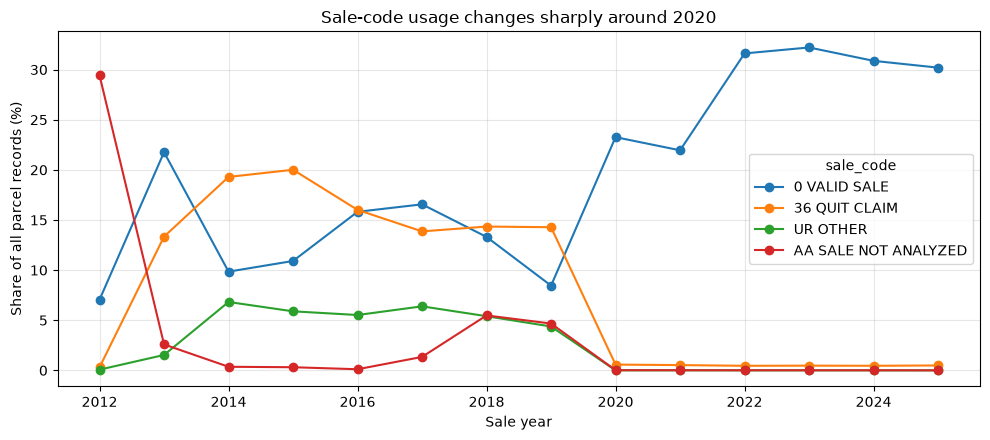

,sale_year,median_valid,median_code_36_quit_claim,code_36_with_quit_claim_instrument,code_36_records,median_code_ur
0,2012,137000.0,95600.0,10,100,192750.0
1,2013,137900.0,125000.0,162,4330,157900.0
2,2014,156000.0,126875.0,214,6380,120000.0
3,2015,167500.0,134900.0,153,6842,120000.0
4,2016,155000.0,137000.0,154,5671,123000.0
5,2017,162000.0,139900.0,162,4866,118000.0
6,2018,165900.0,157000.0,145,5194,117000.0
7,2019,168000.0,170000.0,152,5063,105000.0
8,2020,196900.0,7000.0,178,186,1100.0
9,2021,212000.0,9500.0,190,193,225000.0


In [21]:
code_counts = q("""
    SELECT sale_year, SALECODE || ' ' || SALEDESC AS sale_code, count(*) AS records
    FROM candidate
    WHERE sale_year <= 2025 AND SALECODE IN ('0', '14', '9', '36', 'UR', '99', 'AA', 'DT', '35')
    GROUP BY ALL
""").pivot(index='sale_year', columns='sale_code', values='records').fillna(0)
totals = q('SELECT sale_year, count(*) AS records FROM candidate WHERE sale_year <= 2025 GROUP BY 1').set_index('sale_year').records
code_share = code_counts.div(totals, axis=0) * 100
display(code_share.round(1))

shown_codes = ['0 VALID SALE', '36 QUIT CLAIM', 'UR OTHER', 'AA SALE NOT ANALYZED']
axis = code_share[shown_codes].plot(marker='o')
axis.set(title='Sale-code usage changes sharply around 2020',
         xlabel='Sale year', ylabel='Share of all parcel records (%)')
plt.tight_layout()
plt.show()

display(q("""
    SELECT sale_year,
           median(price_usd) FILTER (WHERE SALECODE = '0') AS median_valid,
           median(price_usd) FILTER (WHERE SALECODE = '36') AS median_code_36_quit_claim,
           count(*) FILTER (WHERE SALECODE = '36' AND INSTRTYP = 'QC') AS code_36_with_quit_claim_instrument,
           count(*) FILTER (WHERE SALECODE = '36') AS code_36_records,
           median(price_usd) FILTER (WHERE SALECODE = 'UR') AS median_code_ur
    FROM candidate WHERE sale_year <= 2025 AND (deed_parcels = 1 OR deed_parcels IS NULL) AND price_usd >= 1000
    GROUP BY 1 ORDER BY 1
"""))

**Findings: sale-code usage changes around 2020**

The most surprising result of the EDA. It looks like a change in how the assessor classifies sales, but the cause is not confirmed.

- The share coded `0 VALID SALE` is 7% in 2012, 22% in 2013, and 10-17% in 2014-2019, versus 22-32% from 2020 on.
- Before 2020, code `36 QUIT CLAIM` is used on 4,000-7,000 rows a year, mostly on non-quit-claim instruments, at market-like medians ($125k-$170k). From 2020 it covers about 150 rows a year at around $10k.
- `UR OTHER` disappears after 2020, and `AA SALE NOT ANALYZED` covers 29% of 2012 records.
- Sheriff sales fall from about 1,400-1,800 a year (2012-2016) to about 470 in 2020-2021, then stay near 600. City treasurer sales nearly vanish after 2013.
- **Implication:** valid-sale counts and medians before and after 2020 are not directly comparable, so the published output starts in 2020. Monitoring code shares on refresh would be a useful addition (not implemented).

sales                median_price               
area      Pittsburgh Rest of county   Pittsburgh Rest of county
sale_year                                                      
2012           275.0         2090.0      89000.0       142000.0
2013          1211.0         6192.0     106000.0       142500.0
2014           571.0         2737.0     139900.0       160000.0
2015           731.0         3043.0     142250.0       172000.0
2016          1007.0         4678.0     136000.0       159900.0
2017           933.0         4904.0     138900.0       165000.0
2018           588.0         4267.0     145000.0       169900.0
2019           398.0         2612.0     132000.0       172950.0
2020          1193.0         7013.0     185000.0       199000.0
2021          1489.0         7313.0     195000.0       215000.0
2022          2164.0         8835.0     218650.0       229900.0
2023          2030.0         7893.0     236000.0       244500.0
2024          1902.0         7681.0     250000.0       259900.0
2025          1860.0         7656.0     259700.0       270000.0
2026          1269.0         5778.0     273000.0       288000.0

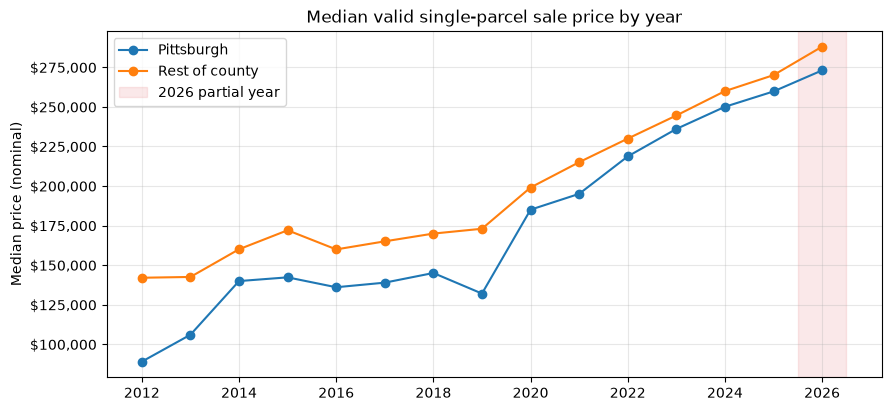

In [22]:
# County-wide price trend: Pittsburgh vs. the rest of the county.
trend = q("""
    SELECT sale_year,
           CASE WHEN municipality = 'PITTSBURGH' THEN 'Pittsburgh' ELSE 'Rest of county' END AS area,
           count(*) AS sales, median(price_usd) AS median_price
    FROM market_sales GROUP BY ALL ORDER BY ALL
""")
display(trend.pivot(index="sale_year", columns="area", values=["sales", "median_price"]))

fig, ax = plt.subplots()
for area, frame in trend.groupby("area"):
    ax.plot(frame["sale_year"], frame["median_price"], marker="o", label=area)
ax.axvspan(2025.5, 2026.5, color="tab:red", alpha=0.1, label="2026 partial year")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Median valid single-parcel sale price by year")
ax.set_ylabel("Median price (nominal)")
ax.legend()
plt.show()

**Findings**

| Area | 2012 median | 2025 median |
| --- | ---: | ---: |
| Pittsburgh | $89k (275 sales) | $260k |
| Rest of county | $142k | $270k |

The nominal city-suburb gap narrows from about $50k to $10k. Part of the 2019-2020 jump may come from the sale-code change rather than prices, and the 2012 Pittsburgh figure rests on only 275 sales.

In [23]:
change = q("""
    SELECT municipality,
           count(*) FILTER (WHERE sale_year BETWEEN 2015 AND 2017) AS sales_2015_2017,
           count(*) FILTER (WHERE sale_year BETWEEN 2023 AND 2025) AS sales_2023_2025,
           median(price_usd) FILTER (WHERE sale_year BETWEEN 2015 AND 2017) AS median_2015_2017,
           median(price_usd) FILTER (WHERE sale_year BETWEEN 2023 AND 2025) AS median_2023_2025
    FROM market_sales
    WHERE sale_year BETWEEN 2015 AND 2017 OR sale_year BETWEEN 2023 AND 2025
    GROUP BY municipality
""")
eligible = change.loc[(change.sales_2015_2017 >= 30) & (change.sales_2023_2025 >= 30)].copy()
eligible['pct_change'] = (eligible.median_2023_2025 / eligible.median_2015_2017 - 1) * 100
eligible = eligible.sort_values('pct_change')
print(f'{len(eligible)} of {len(change)} municipalities have at least 30 sales in both periods.')
print(f"Median municipality change: {eligible['pct_change'].median():.0f}%")
print('Ten lowest and ten highest changes; exploratory comparison across the coding break.')
display(pd.concat([eligible.head(10), eligible.tail(10)]).round(1))

77 of 130 municipalities have at least 30 sales in both periods.
Median municipality change: 66%
Ten lowest and ten highest changes; exploratory comparison across the coding break.


,municipality,sales_2015_2017,sales_2023_2025,median_2015_2017,median_2023_2025,pct_change
84,Sewickley,93,151,330000.0,446000.0,35.2
83,Aspinwall,58,64,279750.0,390250.0,39.5
56,Pennsbury Village,43,79,117000.0,168025.0,43.6
67,Ohio,104,168,327000.0,470000.0,43.7
88,Moon,466,708,215000.0,310000.0,44.2
49,Collier,127,207,275000.0,400000.0,45.5
59,Crescent,43,75,155000.0,229500.0,48.1
117,O'Hara,169,266,303500.0,450000.0,48.3
110,Carnegie,117,190,147500.0,220000.0,49.2
97,Kennedy,146,236,179950.0,270500.0,50.3


**Findings**

- 77 of 130 municipalities have at least 30 valid sales in both periods. Their median price change from 2015-2017 to 2023-2025 is **+66%** (nominal).
- **Largest increases (about +90% to +130%):** Clairton, Etna, McKeesport, Edgeworth, Glassport, Jefferson Hills, Penn Hills, Munhall, Port Vue, Coraopolis, mostly lower-priced Mon Valley boroughs.
- **Smallest increases (about +35% to +50%):** Sewickley, Aspinwall, Pennsbury Village, Ohio, Moon, Collier, Crescent, O'Hara, Carnegie, Kennedy, mostly higher-priced suburbs.
- This looks like price convergence, but percent changes from low bases are volatile and both periods straddle the 2020 coding change.
- Pooling three years per period was necessary; single-year medians are too noisy for most municipalities.

## 10. Candidate questions

| Question | What the EDA supports | Main caveat |
| --- | --- | --- |
| **How has the median market sale price changed by municipality and year, and which municipalities rose fastest?** | Annual medians and year-over-year rankings | Small samples; changing sale mix; nominal prices |
| Is the Pittsburgh vs. suburban price gap closing? | Exploratory comparison above | Must pool sales, not average municipality medians |
| Where are distressed transfers concentrated? | Sheriff, treasurer, and government counts | Court schedules and coding affect counts |
| What share of transfers are non-market? | Sale-code shares | Code usage changes around 2020 |
| How many transactions happen each year? | Counting real deeds | Parcel rows are not transactions |

**Chosen question:** the first. It uses the cleanest subset and depends on the key cleaning decisions found above: ward roll-up, multi-parcel deeds, validity codes, and partial years.

**Output:** `output.municipality_year_sales`, one row per municipality and completed sale year from **2020**, with sale count, median price, a low-sample flag, year-over-year change, and a growth rank within each year. A municipality is ranked only if it has at least **30 sales in both years**. Notebook 2 answers the question from this table.

## 11. Cleaning rules and quality checks

### Rules implemented in the pipeline

| Field | Rule | Evidence |
| --- | --- | --- |
| Grain | One row per parcel on a deed; `(PARID, original DEEDBOOK, original DEEDPAGE, SALEDATE)` must be unique. `_id` is not a key. | Section 1 |
| Text | Trim text and normalize municipality names; blank optional values become `NULL`. | 71% of municipality names padded |
| Sale date | Strict ISO parsing; the sale date (not recording date) sets the year. | Section 3 |
| Recording date | Blank or before 2000 becomes `NULL` and is flagged; no guessed corrections. | `0212-08-01` |
| Price | Blank is `NULL`, never zero; unusual prices are kept in the cleaned layer. | Section 5 |
| Deed | Placeholder references become `NULL` (originals kept); `TR##` books are real. Parcel counts use all source rows. | Section 7 |
| Municipality | Roll ward code ranges up into their four cities. | 175 codes = 130 municipalities |
| Market sale | Code `0`, price at least $1,000, and a single-parcel or unknown deed (unknown is flagged). | Sections 6-7 |
| Published years | Completed years from 2020; keep low-sample groups but rank only with 30 sales in both years. | Sections 4, 8, 9 |

### Checks that fail a run

| Check | Why it matters |
| --- | --- |
| Required fields, strict date/price parsing, nonnegative prices, unique natural key | Reject malformed or duplicate rows |
| **No pre-2000 recording date survives; more than one flagged anomaly fails** | **Dataset-driven:** the `0212-08-01` record |
| **Unknown deed references have no parcel count; each real deed contributes at most one market-sale row** | **Dataset-driven:** placeholder groups and the 3.9x overstatement |
| Ward roll-up yields 130 municipalities; codes belong to known sets | Catch mapping drift and new codes |
| Raw and cleaned row counts match | Cleaning must not drop or add rows |
| Output keys unique, years in range, counts positive, totals equal qualifying sales | Catch aggregation errors |

These checks live in `src/pipeline.py` (see `docs/pipeline.md`) and are covered by pytest with deliberately bad inputs.

### Limitations

- The cause of the 2020 sale-code change is not confirmed with the assessor.
- Prices are nominal, and the source has no property-use field to restrict to residential.
- The 30-sale cutoff is a practical guard, not a statistical guarantee.